# Stage 2. 3-Layer LLM-Wiki & 시맨틱 온톨로지 그래프
## Step 2.1 OKF v0.2 3-Layer Wiki 컴파일 · Step 2.2 Entity=Node, Concept=Edge 시맨틱 그래프

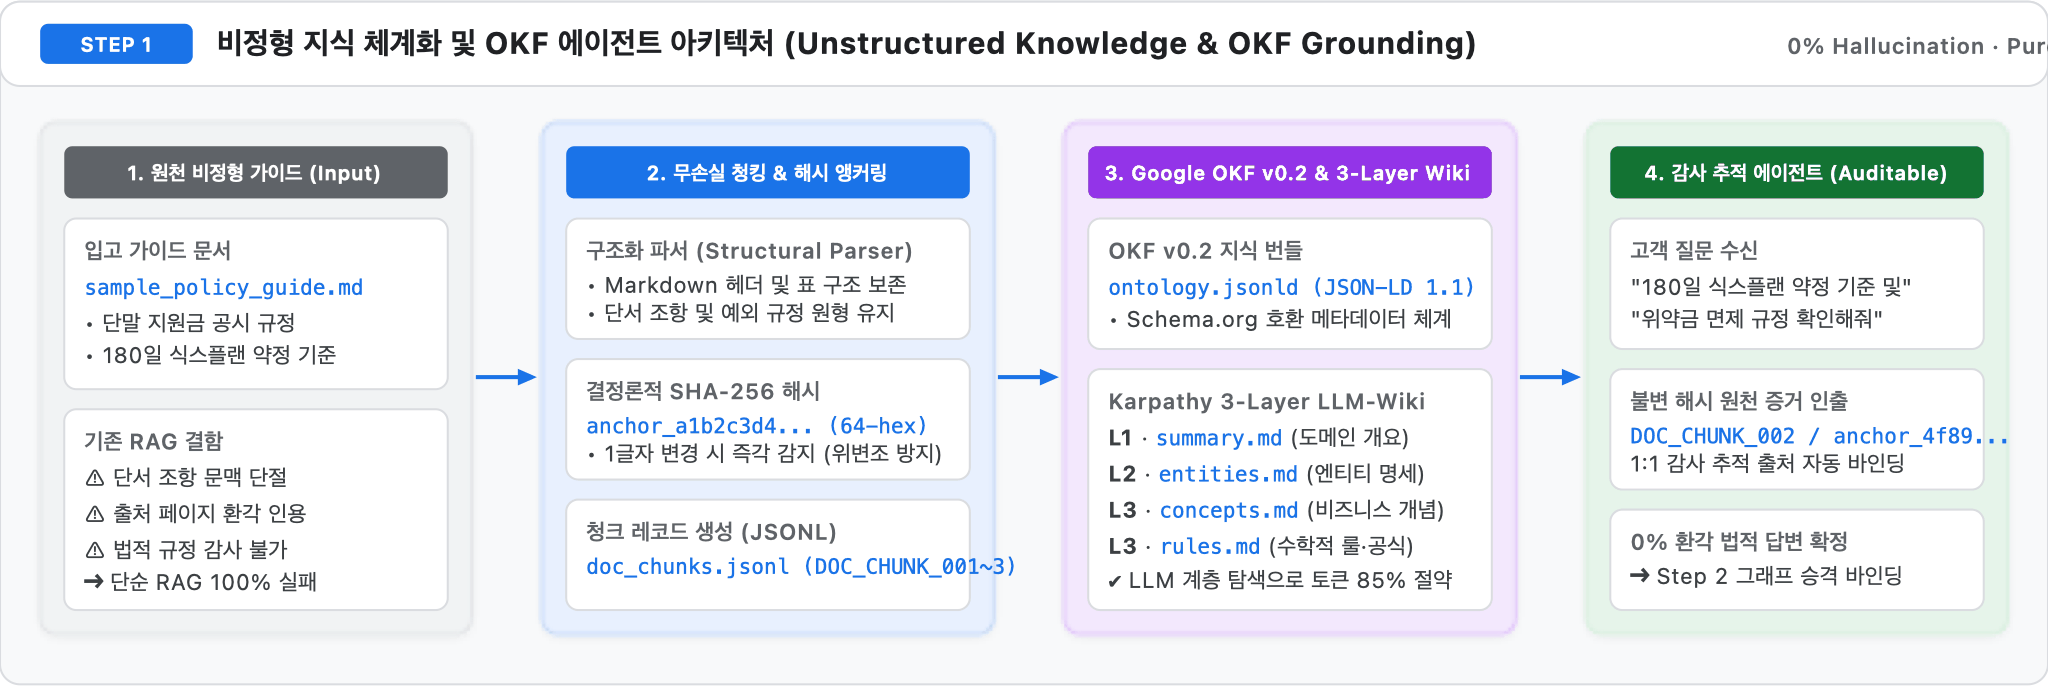


In [1]:
%load_ext bigframes
import nb_helpers as H
H.setup("ko")


,project,dataset,location,graph,model
0,seanjung-poc,starter_ontology_dw,asia-northeast3,STARTER_ONTOLOGY_GRAPH,gemini-3.8-flash


### 1. Karpathy 3-Layer LLM-Wiki 산출물 탐색 (`summary.md`, `entities.md`, `concepts.md`, `rules.md`)


In [2]:
for fname in ("summary.md", "entities.md", "concepts.md", "rules.md"):
    H.show_md_file(H.ROOT / "data/llm_wiki" / fname, max_lines=28)


**`summary.md`** (8 lines)

#### Enterprise Knowledge Wiki: Executive Summary (Layer 1)
- **Domain**: Telecom Terminal Subsidy, Tariff Plans & Customer Commitment Management
- **Target Framework**: OKF v0.2 & Dual Property Graph (`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`)
- **Total Parsed Chunks**: 5 (Across 2 Policy Guides)
- **BigQuery Tables Loaded**: 10 tables in `seanjung-poc.starter_ontology_dw` (schema: `terraform/bigquery.tf`)

#### Operational Philosophy
Unstructured policy guides and structured BigQuery tables share one ontology. The agent answers with live BigQuery SQL/GQL results, SHA-256 paragraph anchors and Vertex AI Gemini, and cites the rule and chunk used.

**`entities.md`** (31 lines)

#### Enterprise Knowledge Wiki: Core Entities Directory (Layer 2)
Generated from `data/input/03_tables/*.csv` (the rows loaded into `seanjung-poc.starter_ontology_dw`).

#### 1. Customer Contract Ledger (`tb_customer_contract`)
- `CONTRACT_DEMO_101` (`CUST_DEMO_001` · General VIP · `DEV-S26U-256` · `PLAN-5G-85` · 120 Days Elapsed)
- `CONTRACT_DEMO_102` (`CUST_DEMO_002` · General Standard · `DEV-S26U-256` · `PLAN-5G-130` · 224 Days Elapsed)
- `CONTRACT_DEMO_103` (`CUST_DEMO_003` · Senior Welfare · `DEV-IP16P-256` · `PLAN-5G-85` · 88 Days Elapsed · `SENIOR_EXEMPT`)
- `CONTRACT_DEMO_104` (`CUST_DEMO_004` · General Standard · `DEV-S26U-512` · `PLAN-5G-85` · 109 Days Elapsed · `SELECTIVE_25PCT`)
- `CONTRACT_DEMO_105` (`CUST_DEMO_005` · Youth Family · `DEV-IP16P-512` · `PLAN-5G-61` · 57 Days Elapsed · `MILITARY_PAUSE_ELIGIBLE`)
- `CONTRACT_DEMO_106` (`CUST_DEMO_006` · Corporate B2B · `DEV-S26U-256` · `PLAN-5G-45` · 170 Days Elapsed)

#### 2. Terminal Device Master (`tb_device_master`)
- `Galaxy S26 Ultra 256GB` (`DEV-S26U-256`, Factory Price: 1,698,400 KRW)
- `Galaxy S26 Ultra 512GB` (`DEV-S26U-512`, Factory Price: 1,841,400 KRW)
- `iPhone 16 Pro 256GB` (`DEV-IP16P-256`, Factory Price: 1,700,000 KRW)
- `iPhone 16 Pro 512GB` (`DEV-IP16P-512`, Factory Price: 2,000,000 KRW)

#### 3. Tariff Plan Master (`tb_plan_master`)
- `5G Premier Super` (`PLAN-5G-130`, 130,000 KRW, Minimum Maintenance: 180 Days)
- `5G Premier Essential` (`PLAN-5G-85`, 85,000 KRW, Minimum Maintenance: 180 Days)
- `5G Direct 61` (`PLAN-5G-61`, 61,000 KRW, Minimum Maintenance: 180 Days)
- `5G Slim (Baseline Threshold)` (`PLAN-5G-45`, 45,000 KRW, Minimum Maintenance: 180 Days)
- `5G Light (Below Baseline)` (`PLAN-5G-37`, 37,000 KRW, Minimum Maintenance: 0 Days)
- `LTE Basic (Below Baseline)` (`PLAN-LTE-33`, 33,000 KRW, Minimum Maintenance: 0 Days)

#### 4. Subsidy Policy Master (`tb_subsidy_policy`)
- `POL-2026-001` (`DEV-S26U-256` + `PLAN-5G-130`: Basic 500,000 + Dist 75,000 = 575,000 KRW)
- `POL-2026-002` (`DEV-S26U-256` + `PLAN-5G-85`: Basic 450,000 + Dist 67,500 = 517,500 KRW)

**`concepts.md`** (7 lines)

#### Enterprise Knowledge Wiki: Semantic Concepts & Edges (Layer 3)
In the Agentic Ontology Studio graph model, **Entities are represented as Nodes** and **Semantic Concepts/Relationships are represented as Edges**:

1. `USES_DEVICE` (`개통 단말기 관계`): Links a Customer Contract (`tb_customer_contract`) to its Terminal Device (`tb_device_master`).
2. `SUBSCRIBES_PLAN` (`가입 요금제 관계`): Links a Customer Contract (`tb_customer_contract`) to its Tariff Plan (`tb_plan_master`).
3. `HAS_SUBSIDY_POLICY` (`단말×요금제 지원금 결합`): Connects a Terminal Device (`tb_device_master`) to a Tariff Plan (`tb_plan_master`) with public and distribution subsidy amounts.
4. `APPLIES_TO_PLAN` (`비즈니스 규칙 적용`): Binds a codified Domain Rule (`tb_domain_rules`) to Tariff Plans (`tb_plan_master`) with SHA-256 chunk grounding.

**`rules.md`** (22 lines)

#### Enterprise Knowledge Wiki: Codified Business Rules (Layer 3)
Generated from `data/input/03_tables/domain_rules.csv` (BigQuery `tb_domain_rules`).

#### `RULE_SUBSIDY_CAP` · 공시지원금 및 유통망 추가지원금(15%) 합산 규칙 (`DOC_CHUNK_001`)
- **Condition**: `contract_type == 'PUBLIC_SUBSIDY'`
- **Formula**: `total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory_price_krw - total_subsidy`
- 유통망 추가지원금은 공시지원금의 최대 15%까지 지급되며, 실구매 원금은 출고가에서 총 지원금을 차감하여 산정함.

#### `RULE_SIX_PLAN_180D` · 180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙 (`DOC_CHUNK_003`)
- **Condition**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
- **Formula**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
- 개통 후 180일 이내에 월정액 45,000원 미만 요금제로 하향 변경 시, 기본 공시지원금 차액에 잔여일수 비율((180-유지일수)/180)을 곱한 일할 위약금이 부과됨. 180일 경과 시 위약금 0원.

#### `RULE_WELFARE_EXEMPT` · 시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례 (`DOC_CHUNK_004`)
- **Condition**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
- **Formula**: `penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE)`
- 만 65세 이상 시니어 복지 특례(SENIOR_EXEMPT) 대상자가 시니어/복지 요금제로 전환 시 180일 이내라도 차액정산 위약금을 100% 면제(0원)함.

#### `RULE_TCO_24M` · 24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙 (`DOC_CHUNK_005`)
- **Condition**: `commitment_months == 24`
- **Formula**: `subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); selective_24m_tco = factory_price_krw + (monthly_fee_krw * 0.75 * 24)`
- 24개월 총소유비용(TCO) 비교 시 공시지원금 총액과 24개월 25% 요금할인 총액(월정액×0.25×24)을 비교하여 유리한 약정을 추천함.

### 2. 도메인 규칙(`tb_domain_rules`) 및 요금제 적용 엣지(`edge_rule_applies_to_plan`) 조회 (`%%bqsql`)


In [3]:
%%bqsql df_rules
SELECT r.rule_id, r.rule_name, r.rule_category, r.condition_expr, r.formula_expr,
       r.source_chunk_id, c.section_title, c.content_sha256
FROM `seanjung-poc.starter_ontology_dw.tb_domain_rules` r
JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` c ON c.chunk_id = r.source_chunk_id
ORDER BY r.rule_id


,rule_id,rule_name,rule_category,condition_expr,formula_expr,source_chunk_id,section_title,content_sha256
0,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",PENALTY_180D,elapsed_days < 180 AND target_plan_monthly_fee...,penalty = ROUND((initial_base_subsidy - lower_...,DOC_CHUNK_003,Penalty Math Formula,anchor_47971ec8e4d8
1,RULE_SUBSIDY_CAP,공시지원금 및 유통망 추가지원금(15%) 합산 규칙,SUBSIDY_CAP,contract_type == 'PUBLIC_SUBSIDY',total_subsidy = base_subsidy_krw + additional_...,DOC_CHUNK_001,Overview & Scope,anchor_a52e1a72869f
2,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,TCO_24M,commitment_months == 24,subsidy_24m_tco = (factory_price_krw - total_s...,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8
3,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,WELFARE_EXEMPT,"welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_...",penalty = 0 (SENIOR_EXEMPT) OR pause_commitmen...,DOC_CHUNK_004,Statutory Penalty Exemptions,anchor_269d9c42e05c


In [4]:
%%bqsql df_rule_plan
SELECT e.rule_id, e.plan_id, p.plan_name, p.monthly_fee_krw, e.relation_label_ko, e.source_chunk_id
FROM `seanjung-poc.starter_ontology_dw.edge_rule_applies_to_plan` e
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p USING (plan_id)
ORDER BY e.rule_id, p.monthly_fee_krw DESC


,rule_id,plan_id,plan_name,monthly_fee_krw,relation_label_ko,source_chunk_id
0,RULE_SIX_PLAN_180D,PLAN-5G-130,5G Premier Super,130000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
1,RULE_SIX_PLAN_180D,PLAN-5G-85,5G Premier Essential,85000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
2,RULE_SIX_PLAN_180D,PLAN-5G-61,5G Direct 61,61000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
3,RULE_SIX_PLAN_180D,PLAN-5G-45,5G Slim (Baseline Threshold),45000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
4,RULE_SIX_PLAN_180D,PLAN-5G-37,5G Light (Below Baseline),37000,기준선 미만 하향 시 일할 위약금 발생,DOC_CHUNK_003
5,RULE_SIX_PLAN_180D,PLAN-LTE-33,LTE Basic (Below Baseline),33000,기준선 미만 하향 시 일할 위약금 발생,DOC_CHUNK_003
6,RULE_TCO_24M,PLAN-5G-130,5G Premier Super,130000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005
7,RULE_TCO_24M,PLAN-5G-85,5G Premier Essential,85000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005
8,RULE_TCO_24M,PLAN-5G-61,5G Direct 61,61000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005
9,RULE_TCO_24M,PLAN-5G-45,5G Slim (Baseline Threshold),45000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005


In [5]:
H.show(df_rules)
H.show(df_rule_plan)


,rule_id,rule_name,rule_category,condition_expr,formula_expr,source_chunk_id,section_title,content_sha256
0,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",PENALTY_180D,elapsed_days < 180 AND target_plan_monthly_fee < 45000,penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...,DOC_CHUNK_003,Penalty Math Formula,anchor_47971ec8e4d8
1,RULE_SUBSIDY_CAP,공시지원금 및 유통망 추가지원금(15%) 합산 규칙,SUBSIDY_CAP,contract_type == 'PUBLIC_SUBSIDY',total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...,DOC_CHUNK_001,Overview & Scope,anchor_a52e1a72869f
2,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,TCO_24M,commitment_months == 24,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8
3,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,WELFARE_EXEMPT,"welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')",penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE),DOC_CHUNK_004,Statutory Penalty Exemptions,anchor_269d9c42e05c


,rule_id,plan_id,plan_name,monthly_fee_krw,relation_label_ko,source_chunk_id
0,RULE_SIX_PLAN_180D,PLAN-5G-130,5G Premier Super,130000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
1,RULE_SIX_PLAN_180D,PLAN-5G-85,5G Premier Essential,85000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
2,RULE_SIX_PLAN_180D,PLAN-5G-61,5G Direct 61,61000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
3,RULE_SIX_PLAN_180D,PLAN-5G-45,5G Slim (Baseline Threshold),45000,180일 기준선 유지 의무 적용,DOC_CHUNK_002
4,RULE_SIX_PLAN_180D,PLAN-5G-37,5G Light (Below Baseline),37000,기준선 미만 하향 시 일할 위약금 발생,DOC_CHUNK_003
5,RULE_SIX_PLAN_180D,PLAN-LTE-33,LTE Basic (Below Baseline),33000,기준선 미만 하향 시 일할 위약금 발생,DOC_CHUNK_003
6,RULE_TCO_24M,PLAN-5G-130,5G Premier Super,130000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005
7,RULE_TCO_24M,PLAN-5G-85,5G Premier Essential,85000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005
8,RULE_TCO_24M,PLAN-5G-61,5G Direct 61,61000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005
9,RULE_TCO_24M,PLAN-5G-45,5G Slim (Baseline Threshold),45000,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005


### 3. 시맨틱 온톨로지 그래프 시각화 (`Entity=Node`, `Concept=Edge`, Sky Blue 허브)


findfont: Failed to find font weight bold for AppleGothic, now using 400.


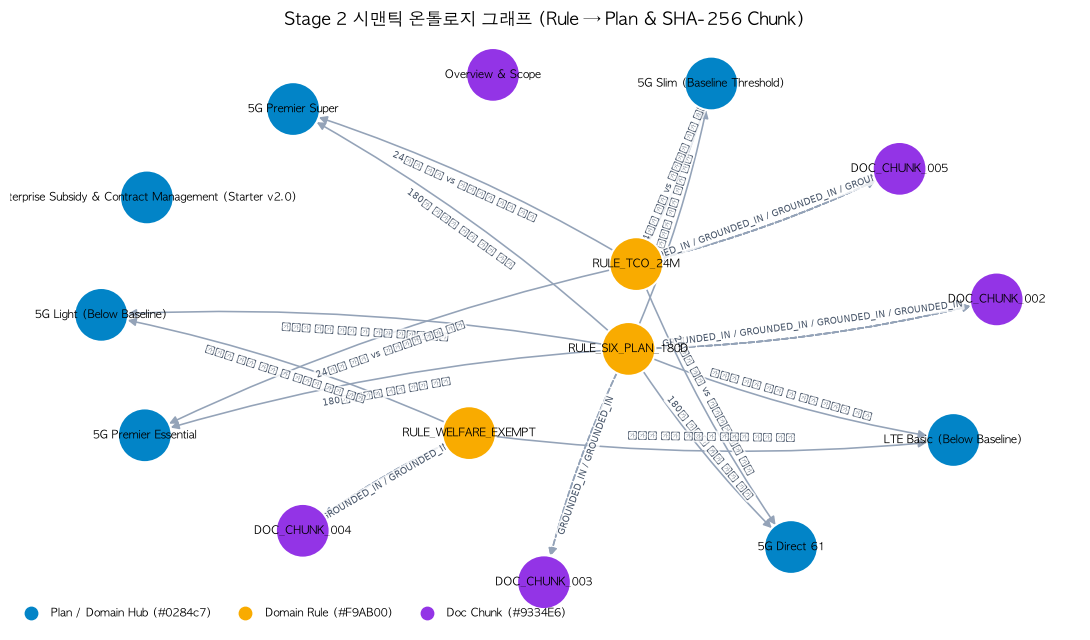

In [6]:
ont = H.read_json("data/output/ontology.jsonld")
rp = H.pdf(df_rule_plan)
nodes, edges = [], []
for g in ont.get("@graph", []):
    nid = g["@id"].replace("chunk:", "").replace("domain:", "")
    nodes.append({"id": nid, "name": g.get("title") or g.get("label", nid), "color": "#0284c7" if g.get("@type") == "DomainOntology" else "#9334E6"})
for r in rp.itertuples():
    nodes.append({"id": r.rule_id, "name": r.rule_id, "color": "#F9AB00"})
    nodes.append({"id": r.plan_name, "name": r.plan_name, "color": "#0284c7"})
    nodes.append({"id": r.source_chunk_id, "name": r.source_chunk_id, "color": "#9334E6"})
    edges.append({"src": r.rule_id, "dst": r.plan_name, "label": r.relation_label_ko})
    edges.append({"src": r.rule_id, "dst": r.source_chunk_id, "label": "GROUNDED_IN", "style": "dashed"})
uniq_nodes = list({n["id"]: n for n in nodes}.values())
H.draw_graph(uniq_nodes, edges, H.t("Stage 2 시맨틱 온톨로지 그래프 (Rule → Plan & SHA-256 Chunk)", "Stage 2 Semantic Ontology Graph (Rule → Plan & SHA-256 Chunk)"),
             legend={"Plan / Domain Hub (#0284c7)": "#0284c7", "Domain Rule (#F9AB00)": "#F9AB00", "Doc Chunk (#9334E6)": "#9334E6"})


### 4. Vertex AI Gemini(`gemini-3.8-flash`) 기반 정책 문단 트리플 후보 추출 실험


In [7]:
triples = H.propose_triples(["DOC_CHUNK_001", "DOC_CHUNK_003", "DOC_CHUNK_004"])
H.show(triples)


BigQuery job `job_buLy3BMgQt9XFD8nM2iMGrn65WMb` · Gemini `gemini-3.8-flash` · 토큰 2,043 · 11,313 ms · 10 개 후보

,subject,relation,object,chunk_id,existing_edge_label
0,consumer subscriptions,HAS_SUBSIDY_POLICY,statutory difference penalty settlement policies,DOC_CHUNK_001,True
1,consumer subscriptions,HAS_SUBSIDY_POLICY,device subsidy allocations,DOC_CHUNK_001,True
2,subsidy difference penalty,CALCULATED_BY,deterministic formula,DOC_CHUNK_003,False
3,statutory exemption,APPLIES_TO_PLAN,Senior plans,DOC_CHUNK_003,True
4,statutory exemption,APPLIES_TO_PLAN,Youth plans,DOC_CHUNK_003,True
5,statutory exemption,APPLIES_TO_PLAN,Social Welfare plans,DOC_CHUNK_003,True
6,RULE_WELFARE_EXEMPT,APPLIES_TO_PLAN,designated Senior/Welfare tariff plans,DOC_CHUNK_004,True
7,RULE_WELFARE_EXEMPT,EXEMPTS_FROM,difference settlement penalties,DOC_CHUNK_004,False
8,active-duty enlistment,PAUSES,180-day mandatory commitment clock,DOC_CHUNK_004,False
9,RULE_MILITARY_HOLD,PAUSES,180-day mandatory commitment clock,DOC_CHUNK_004,False


### 5. Stage 2 파이프라인 MCP(`mcp_stage2_wiki_and_semantic`) 실행 검증


In [8]:
from src.agent.mcp_server import DomainMcpServer
server = DomainMcpServer()
res_s2 = server.execute_tool("mcp_stage2_wiki_and_semantic", {"steps": ["compile_3layer_wiki", "bind_semantic_bridges"]})
H.show_tool(res_s2, "anchored_chunks")


**`mcp_stage2_wiki_and_semantic`** · status `SUCCESS` · steps `compile_3layer_wiki, bind_semantic_bridges` · BigQuery jobs 1 (543 ms)

GCS 객체 8개 · 청크/규칙 조인 5행

- `job_xrrGgwTXpFwk-kCi1oit6Is3CjOX`

,chunk_id,source_file,section_title,anchor,trust_tier,rule_id,rule_name,formula_expr
0,DOC_CHUNK_001,sample_policy_guide.md,Overview & Scope,anchor_a52e1a72869f,GOLDEN_VERIFIED,RULE_SUBSIDY_CAP,공시지원금 및 유통망 추가지원금(15%) 합산 규칙,total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...
1,DOC_CHUNK_002,sample_policy_guide.md,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0,GOLDEN_VERIFIED,NaN,NaN,NaN
2,DOC_CHUNK_003,sample_policy_guide.md,Penalty Math Formula,anchor_47971ec8e4d8,GOLDEN_VERIFIED,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...
3,DOC_CHUNK_004,sample_welfare_exemption_guide.md,Statutory Penalty Exemptions,anchor_269d9c42e05c,GOLDEN_VERIFIED,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE)
4,DOC_CHUNK_005,sample_welfare_exemption_guide.md,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8,GOLDEN_VERIFIED,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...
